# 04. Store Item Demand - регрессия

Регрессия на временном ряду: предсказать `sales` (продажи товара в магазине за день) по истории продаж и календарю.

**Датасет:** 913 000 × 4 (10 магазинов × 50 товаров × 1 826 дней, 2013-01-01 - 2017-12-31).

**Постановка:** прогноз **на 1 день вперёд** - вчерашние продажи уже известны (лаг 1 допустим).

**Протокол:**

1. Проверка данных; календарные признаки и лаги `1/7/30` внутри пары `(store, item)`.
2. Подвыборка 30 пар `(store, item)` **за весь период** (скорость SVR/kNN на 2 ядрах).
3. Разбиение по времени: **train = 2013-2016, test = 2017**.
4. CV на train: `TimeSeriesSplit(5)` **по датам** (день целиком попадает в один фолд).
5. Наивные бейзлайны (вчера / неделю назад) + 10 моделей, метрики RMSE, MAE, MAPE для всех.
6. Подбор гиперпараметров `RandomizedSearchCV` (внутренний `TimeSeriesSplit(3)` по датам).
7. Финальная оценка на 2017 годе.

In [1]:
import sys
from pathlib import Path

KAGGLE_CONFIG_PATHS = [
    Path("/kaggle/input/project-config"),
    Path("/kaggle/input/kirylloffix/project-config"),
]

for p in KAGGLE_CONFIG_PATHS:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
        break

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
print(config)

Config(mode='local', credit='/home/claude/proj/data/credit_risk_dataset.csv', churn='/home/claude/proj/data/WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='/home/claude/proj/data/train.csv', random_state=42)


In [2]:
DATASET = 'demand'

df_demand = pd.read_csv(config.path_demand)
print("demand:", df_demand.shape)
df_demand.head()

demand: (913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## Проверка данных

- полная ли сетка «пара × день» (иначе лаг `shift(1)` будет не «вчера», а «последний известный день»);
- нулевые продажи - важно для MAPE (деление на 0).

In [3]:
n_pairs = df_demand.groupby(['store', 'item']).ngroups
n_days = df_demand['date'].nunique()
print(f"пар (store, item): {n_pairs}, дней: {n_days}, ожидаемо строк: {n_pairs * n_days}, факт: {len(df_demand)}")
print(f"дубликатов (date, store, item): {df_demand.duplicated(['date', 'store', 'item']).sum()}")
print(f"даты: {df_demand['date'].min()} - {df_demand['date'].max()}")
print(f"нулевых продаж: {(df_demand['sales'] == 0).sum()}")
print(df_demand[df_demand['sales'] == 0])

пар (store, item): 500, дней: 1826, ожидаемо строк: 913000, факт: 913000
дубликатов (date, store, item): 0


даты: 2013-01-01 - 2017-12-31
нулевых продаж: 1
             date  store  item  sales
64289  2014-01-15      6     4      0


Сетка полная, дубликатов нет -> `shift(k)` внутри пары действительно означает «k дней назад».

Ровно одна строка с `sales = 0`. Стандартная `mean_absolute_percentage_error` из sklearn на ней даст деление
почти на ноль и огромное число, поэтому MAPE считаем **по строкам с `sales > 0`** (своя функция ниже).

## Препроцессинг: дата, сортировка, календарные признаки

- `date` -> `pd.to_datetime`;
- сортировка по `(store, item, date)` - обязательно для корректных лагов;
- `dayofweek` (0-6), `month` (1-12), `year` (тренд), `day` (1-31).

In [4]:
demand = df_demand.copy()

demand['date'] = pd.to_datetime(demand['date'])
demand = demand.sort_values(['store', 'item', 'date']).reset_index(drop=True)

demand['dayofweek'] = demand['date'].dt.dayofweek
demand['month'] = demand['date'].dt.month
demand['year'] = demand['date'].dt.year
demand['day'] = demand['date'].dt.day

print(f"shape: {demand.shape}")
demand.head()

shape: (913000, 8)


,date,store,item,sales,dayofweek,month,year,day
0,2013-01-01,1,1,13,1,1,2013,1
1,2013-01-02,1,1,11,2,1,2013,2
2,2013-01-03,1,1,14,3,1,2013,3
3,2013-01-04,1,1,13,4,1,2013,4
4,2013-01-05,1,1,10,5,1,2013,5


## Лаги

`sales_lag_1` - вчера, `sales_lag_7` - неделю назад (тот же день недели), `sales_lag_30` - месяц назад.

Лаги считаются **внутри группы** `(store, item)`: иначе первый день товара 2 получил бы продажи последнего дня товара 1.

Первые 30 дней каждой пары (там лаги `NaN`) удаляем - это не пропуски в данных, а отсутствие истории.

In [5]:
for lag in [1, 7, 30]:
    demand[f'sales_lag_{lag}'] = demand.groupby(['store', 'item'])['sales'].shift(lag)

demand = demand.dropna().reset_index(drop=True)

print(f"shape после лагов: {demand.shape}")
demand[['date', 'store', 'item', 'sales', 'sales_lag_1', 'sales_lag_7', 'sales_lag_30']].head()

shape после лагов: (898000, 11)


,date,store,item,sales,sales_lag_1,sales_lag_7,sales_lag_30
0,2013-01-31,1,1,13,9.0,8.0,13.0
1,2013-02-01,1,1,11,13.0,14.0,11.0
2,2013-02-02,1,1,21,11.0,12.0,14.0
3,2013-02-03,1,1,15,21.0,12.0,13.0
4,2013-02-04,1,1,14,15.0,11.0,10.0


## Подвыборка: 30 пар за весь период

898 000 строк - слишком много для SVR и kNN на 2 ядрах, поэтому берём подвыборку.

**Почему не «последние 200 дней», как в прошлой версии.** Тогда в выборке были только даты 2017-06-15 - 2017-12-31:

- `year` был константой (2017) - признак тренда бесполезен;
- первый фолд `TimeSeriesSplit(5)` обучался на ~33 летних днях и проверялся на следующем месяце - модели не видели ни одного полного сезона;
- `TimeSeriesSplit` резал по строкам, а не по датам: один и тот же день попадал частично в train, частично в validation.

**Сейчас:** случайные 30 пар `(store, item)` из 500, но **все их дни**. Каждая модель видит несколько годовых сезонов,
а разбиение делаем по датам.

In [6]:
N_PAIRS = 30

pairs = demand[['store', 'item']].drop_duplicates()
sampled_pairs = pairs.sample(n=N_PAIRS, random_state=RANDOM_STATE)

demand_s = (demand.merge(sampled_pairs, on=['store', 'item'])
                  .sort_values(['date', 'store', 'item'])
                  .reset_index(drop=True))

print(f"пар: {N_PAIRS}, строк: {len(demand_s)}")
print(f"магазинов: {demand_s['store'].nunique()}, товаров: {demand_s['item'].nunique()}")
print(f"даты: {demand_s['date'].min().date()} - {demand_s['date'].max().date()}")
print(f"средние продажи: подвыборка {demand_s['sales'].mean():.2f}, все данные {demand['sales'].mean():.2f}")

пар: 30, строк: 53880
магазинов: 10, товаров: 23
даты: 2013-01-31 - 2017-12-31
средние продажи: подвыборка 63.31, все данные 52.63


## Train / test по времени и CV по датам

- **test = весь 2017 год** (≈ 20% дат). Модель его не видит до финала.
- **train = 2013-01-31 - 2016-12-31.**
- **CV:** `TimeSeriesSplit(5)` применяем к **уникальным датам**, а потом переводим в номера строк.
  Так обучение всегда строго в прошлом, и один день не разрезается между train и validation.

In [7]:
from sklearn.model_selection import TimeSeriesSplit

TEST_START = pd.Timestamp('2017-01-01')

FEATURES = ['store', 'item', 'dayofweek', 'month', 'year', 'day',
            'sales_lag_1', 'sales_lag_7', 'sales_lag_30']

train_mask = demand_s['date'] < TEST_START
train_part = demand_s[train_mask].reset_index(drop=True)
test_part = demand_s[~train_mask].reset_index(drop=True)

X_train, y_train = train_part[FEATURES], train_part['sales']
X_test, y_test = test_part[FEATURES], test_part['sales']
dates_train = train_part['date'].to_numpy()


def date_splits(dates, n_splits):
    """TimeSeriesSplit по уникальным датам -> список (train_idx, val_idx) по строкам."""
    udates = np.unique(dates)
    splits = []
    for tr_d, va_d in TimeSeriesSplit(n_splits=n_splits).split(udates):
        splits.append((np.flatnonzero(np.isin(dates, udates[tr_d])),
                       np.flatnonzero(np.isin(dates, udates[va_d]))))
    return splits


cv_splits = date_splits(dates_train, 5)

print(f"train: {X_train.shape}  ({train_part['date'].min().date()} - {train_part['date'].max().date()})")
print(f"test:  {X_test.shape}  ({test_part['date'].min().date()} - {test_part['date'].max().date()})")
print()
for i, (tr, va) in enumerate(cv_splits):
    print(f"фолд {i}: train {len(tr):6d} строк до {pd.Timestamp(dates_train[tr].max()).date()}, "
          f"val {len(va):5d} строк {pd.Timestamp(dates_train[va].min()).date()} - {pd.Timestamp(dates_train[va].max()).date()}")

train: (42930, 9)  (2013-01-31 - 2016-12-31)
test:  (10950, 9)  (2017-01-01 - 2017-12-31)

фолд 0: train   7230 строк до 2013-09-28, val  7140 строк 2013-09-29 - 2014-05-24
фолд 1: train  14370 строк до 2014-05-24, val  7140 строк 2014-05-25 - 2015-01-17
фолд 2: train  21510 строк до 2015-01-17, val  7140 строк 2015-01-18 - 2015-09-12
фолд 3: train  28650 строк до 2015-09-12, val  7140 строк 2015-09-13 - 2016-05-07
фолд 4: train  35790 строк до 2016-05-07, val  7140 строк 2016-05-08 - 2016-12-31


## Препроцессор, метрики и наивные бейзлайны

**`ColumnTransformer`** - как в классификации: `StandardScaler` к календарю и лагам, `OneHotEncoder` к `store` и `item`.

**Метрики:** RMSE (основная), MAE, MAPE. MAPE - своя функция, только по `sales > 0`.

**Наивные бейзлайны** - обязательная точка отсчёта во временных рядах:

- `Naive_lag1` - «завтра продадим столько же, сколько сегодня»;
- `Naive_lag7` - «столько же, сколько в тот же день прошлой недели» (сезонный наивный прогноз).

Если модель машинного обучения не лучше наивного прогноза - она бесполезна.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error


num_cols_demand = ['dayofweek', 'month', 'year', 'day',
                   'sales_lag_1', 'sales_lag_7', 'sales_lag_30']
cat_cols_demand = ['store', 'item']


def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols_demand),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_demand),
    ])


def make_pipeline_for(model):
    return Pipeline([('prep', make_preprocessor()), ('model', model)])


def mape_nonzero(y_true, y_pred):
    """MAPE по строкам с y_true != 0 (в долях, 0.15 = 15%)."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    m = y_true != 0
    return np.mean(np.abs(y_true[m] - y_pred[m]) / np.abs(y_true[m]))


SCORING = {
    'rmse': 'neg_root_mean_squared_error',
    'mae':  'neg_mean_absolute_error',
    'mape': make_scorer(mape_nonzero, greater_is_better=False),
}


class LagNaiveRegressor(BaseEstimator, RegressorMixin):
    """Наивный прогноз: предсказание = значение лаговой колонки. Ничего не обучает."""

    def __init__(self, lag_col='sales_lag_1'):
        self.lag_col = lag_col

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return X[self.lag_col].to_numpy(dtype=float)


print(f"числовые ({len(num_cols_demand)}): {num_cols_demand}")
print(f"категориальные ({len(cat_cols_demand)}): {cat_cols_demand}")

числовые (7): ['dayofweek', 'month', 'year', 'day', 'sales_lag_1', 'sales_lag_7', 'sales_lag_30']
категориальные (2): ['store', 'item']


## Кросс-валидация: бейзлайны + 10 моделей

Иерархия семейств та же, что для классификации, но регрессоры:

- **Наивные:** Naive_lag1, Naive_lag7 (без обучения);
- **Линейные:** LinearReg, Ridge, Lasso;
- **Деревья:** DecisionTree; **Бэггинг:** RandomForest; **Бустинг:** XGBoost, LightGBM, CatBoost;
- **Метрические:** kNN; **Margin:** SVR (rbf).

Гиперпараметры фиксированные (как в прошлой версии). Метрики по фолдам сохраняются для `05_statistics`.

У моделей `n_jobs=1` (`thread_count=1` у CatBoost): параллелим фолды, а не потоки внутри модели - иначе на 2 ядрах бустинги замедляются в разы.

In [9]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR


baselines = {
    'Naive_lag1': LagNaiveRegressor('sales_lag_1'),
    'Naive_lag7': LagNaiveRegressor('sales_lag_7'),
}

models_demand = {
    'LinearReg':    LinearRegression(),
    'Ridge':        Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso':        Lasso(alpha=0.1, random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    'RandomForest': RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=RANDOM_STATE),
    'XGBoost':      XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                                 random_state=RANDOM_STATE, n_jobs=1),
    'LightGBM':     LGBMRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                                  random_state=RANDOM_STATE, n_jobs=1, verbose=-1),
    'CatBoost':     CatBoostRegressor(iterations=200, depth=6, learning_rate=0.1,
                                      random_state=RANDOM_STATE, verbose=0, allow_writing_files=False, thread_count=1),
    'kNN':          KNeighborsRegressor(n_neighbors=15, n_jobs=1),
    'SVR':          SVR(kernel='rbf', C=1.0, cache_size=1000),
}

fold_rows = []
results_demand = {}

for name, model in {**baselines, **models_demand}.items():
    est = clone(model) if name in baselines else make_pipeline_for(clone(model))
    cvres = cross_validate(est, X_train, y_train, cv=cv_splits, scoring=SCORING,
                           return_train_score=True, n_jobs=-1, error_score='raise')
    rmse, mae, mape = -cvres['test_rmse'], -cvres['test_mae'], -cvres['test_mape']
    for i in range(len(cv_splits)):
        fold_rows.append({'dataset': DATASET, 'model': name, 'fold': i,
                          'rmse': rmse[i], 'mae': mae[i], 'mape': mape[i],
                          'train_rmse': -cvres['train_rmse'][i]})
    results_demand[name] = {
        'rmse_mean': rmse.mean(), 'rmse_std': rmse.std(),
        'mae_mean': mae.mean(), 'mae_std': mae.std(),
        'mape_mean': mape.mean(), 'mape_std': mape.std(),
        'train_rmse': (-cvres['train_rmse']).mean(),
    }
    print(f"{name:13} RMSE {rmse.mean():.4f} ± {rmse.std():.4f} | MAE {mae.mean():.4f} ± {mae.std():.4f} | "
          f"MAPE {mape.mean():.4f} ± {mape.std():.4f} | train RMSE {(-cvres['train_rmse']).mean():.4f}")

Naive_lag1    RMSE 16.0146 ± 1.3374 | MAE 11.8190 ± 0.9252 | MAPE 0.2207 ± 0.0095 | train RMSE 14.8713
Naive_lag7    RMSE 11.9737 ± 0.6448 | MAE 9.2164 ± 0.5286 | MAPE 0.1729 ± 0.0123 | train RMSE 11.2471


LinearReg     RMSE 10.5866 ± 0.3950 | MAE 8.1878 ± 0.2985 | MAPE 0.1576 ± 0.0208 | train RMSE 9.5379


Ridge         RMSE 10.5756 ± 0.3986 | MAE 8.1790 ± 0.3013 | MAPE 0.1574 ± 0.0204 | train RMSE 9.5380


Lasso         RMSE 10.4693 ± 0.6264 | MAE 8.0965 ± 0.4957 | MAPE 0.1552 ± 0.0119 | train RMSE 9.7797


DecisionTree  RMSE 10.9431 ± 0.5892 | MAE 8.3432 ± 0.3842 | MAPE 0.1575 ± 0.0190 | train RMSE 8.0900


...

XGBoost       RMSE 9.3789 ± 0.4292 | MAE 7.2185 ± 0.3246 | MAPE 0.1353 ± 0.0183 | train RMSE 6.6897


LightGBM      RMSE 9.2986 ± 0.4153 | MAE 7.1656 ± 0.3161 | MAPE 0.1345 ± 0.0170 | train RMSE 7.3135


CatBoost      RMSE 9.1721 ± 0.4139 | MAE 7.0834 ± 0.3189 | MAPE 0.1340 ± 0.0143 | train RMSE 8.0776


kNN           RMSE 10.5109 ± 0.5682 | MAE 8.1372 ± 0.4077 | MAPE 0.1537 ± 0.0185 | train RMSE 8.4554


SVR           RMSE 12.4634 ± 2.2537 | MAE 9.2916 ± 1.4002 | MAPE 0.1813 ± 0.0255 | train RMSE 8.6466


## Таблица результатов CV

Сортировка по RMSE **по возрастанию** (меньше - лучше). `RMSE/MAE` - насколько крупные промахи
доминируют в ошибке (для нормального распределения ошибок ≈ 1.25).

In [10]:
results_demand_df = pd.DataFrame(results_demand).T.sort_values('rmse_mean')
results_demand_df['rmse_to_mae'] = results_demand_df['rmse_mean'] / results_demand_df['mae_mean']
pd.set_option('display.width', 200)
print(results_demand_df.round(4))

folds_df = pd.DataFrame(fold_rows)
folds_df.to_csv(config.cv_folds(DATASET), index=False)
print(f"\nМетрики по фолдам сохранены: {config.cv_folds(DATASET)}")

              rmse_mean  rmse_std  mae_mean  mae_std  mape_mean  mape_std  train_rmse  rmse_to_mae
CatBoost         9.1721    0.4139    7.0834   0.3189     0.1340    0.0143      8.0776       1.2949
LightGBM         9.2986    0.4153    7.1656   0.3161     0.1345    0.0170      7.3135       1.2977
XGBoost          9.3789    0.4292    7.2185   0.3246     0.1353    0.0183      6.6897       1.2993
RandomForest     9.6827    0.4597    7.4780   0.3593     0.1421    0.0150      3.3499       1.2948
Lasso           10.4693    0.6264    8.0965   0.4957     0.1552    0.0119      9.7797       1.2931
kNN             10.5109    0.5682    8.1372   0.4077     0.1537    0.0185      8.4554       1.2917
Ridge           10.5756    0.3986    8.1790   0.3013     0.1574    0.0204      9.5380       1.2930
LinearReg       10.5866    0.3950    8.1878   0.2985     0.1576    0.0208      9.5379       1.2930
DecisionTree    10.9431    0.5892    8.3432   0.3842     0.1575    0.0190      8.0900       1.3116
Naive_lag7

## Bar plot

**Чем ниже столбец - тем лучше.** Топ-3 - зелёным, наивные бейзлайны - серым, остальные - синим.

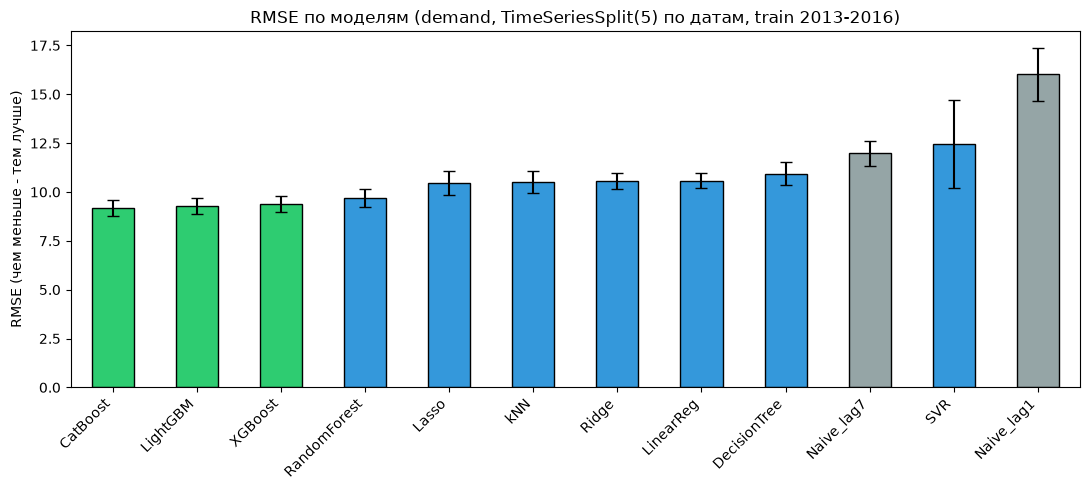

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = []
for i, name in enumerate(results_demand_df.index):
    if name.startswith('Naive'):
        colors.append('#95a5a6')
    elif i < 3:
        colors.append('#2ecc71')
    else:
        colors.append('#3498db')

results_demand_df['rmse_mean'].plot(
    kind='bar', yerr=results_demand_df['rmse_std'], ax=ax,
    color=colors, capsize=4, edgecolor='black'
)
ax.set_title('RMSE по моделям (demand, TimeSeriesSplit(5) по датам, train 2013-2016)')
ax.set_ylabel('RMSE (чем меньше - тем лучше)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(config.demand_plot, dpi=150)
plt.show()

## Подбор гиперпараметров (RandomizedSearchCV)

Для каждой из 10 моделей (бейзлайны не обучаются):

1. `RandomizedSearchCV`, внутренняя валидация `TimeSeriesSplit(3)` **по датам train**;
2. лучшая комбинация переобучается на всём train (2013-2016);
3. одна оценка на тесте 2017.

`n_iter = 15` для большинства, 10 для моделей с одним гиперпараметром, 6 для SVR (самая медленная).

**Важно для SVR:** при `C = 1` и `epsilon = 0.1` SVR почти не может подстроиться под таргет масштаба 50 штук
(штраф за ошибку слишком слабый). Поэтому `C` перебираем до 1000.

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform


param_spaces = {
    'LinearReg': {'model__fit_intercept': [True]},
    'Ridge': {'model__alpha': loguniform(1e-3, 1e3)},
    'Lasso': {'model__alpha': loguniform(1e-4, 1e1)},
    'DecisionTree': {
        'model__max_depth': [4, 6, 8, 10, 12, 15, None],
        'model__min_samples_leaf': randint(1, 200),
    },
    'RandomForest': {
        'model__n_estimators': [200, 300],
        'model__max_depth': [None, 10, 15, 20],
        'model__min_samples_leaf': [1, 5, 10, 20],
        'model__max_features': [0.3, 0.5, 1.0],
    },
    'XGBoost': {
        'model__n_estimators': randint(200, 700),
        'model__max_depth': randint(3, 10),
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__subsample': uniform(0.6, 0.4),
        'model__colsample_bytree': uniform(0.6, 0.4),
        'model__min_child_weight': randint(1, 20),
    },
    'LightGBM': {
        'model__n_estimators': randint(200, 700),
        'model__num_leaves': randint(15, 128),
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__subsample': uniform(0.6, 0.4),
        'model__subsample_freq': [1],
        'model__colsample_bytree': uniform(0.6, 0.4),
        'model__min_child_samples': randint(5, 200),
    },
    'CatBoost': {
        'model__iterations': randint(200, 600),
        'model__depth': randint(4, 9),
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__l2_leaf_reg': loguniform(1, 10),
    },
    'kNN': {
        'model__n_neighbors': randint(5, 150),
        'model__weights': ['uniform', 'distance'],
    },
    'SVR': {
        'model__C': loguniform(1, 1000),
        'model__gamma': ['scale', 0.01, 0.03, 0.1],
        'model__epsilon': [0.1, 1.0, 3.0],
    },
}

N_ITER = {name: 15 for name in models_demand}
N_ITER.update({'LinearReg': 1, 'Ridge': 10, 'Lasso': 10, 'SVR': 6})

inner_splits = date_splits(dates_train, 3)

In [13]:
import time


test_rows = []

for name, model in baselines.items():
    y_pred = model.predict(X_test)
    test_rows.append({'dataset': DATASET, 'model': name,
                      'cv_rmse_default': results_demand[name]['rmse_mean'], 'cv_rmse_tuned': np.nan,
                      'test_rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
                      'test_mae': mean_absolute_error(y_test, y_pred),
                      'test_mape': mape_nonzero(y_test, y_pred),
                      'best_params': '-'})

for name, model in models_demand.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        make_pipeline_for(clone(model)),
        param_distributions=param_spaces[name],
        n_iter=N_ITER[name],
        cv=inner_splits,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        refit=True,
    )
    search.fit(X_train, y_train)
    y_pred = search.best_estimator_.predict(X_test)

    test_rows.append({
        'dataset': DATASET, 'model': name,
        'cv_rmse_default': results_demand[name]['rmse_mean'],
        'cv_rmse_tuned': -search.best_score_,
        'test_rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
        'test_mae': mean_absolute_error(y_test, y_pred),
        'test_mape': mape_nonzero(y_test, y_pred),
        'best_params': {k.replace('model__', ''): (round(float(v), 5) if isinstance(v, (float, np.floating)) else v)
                        for k, v in search.best_params_.items()},
    })
    r = test_rows[-1]
    print(f"{name:13} CV(default) {r['cv_rmse_default']:.4f} -> CV(tuned, 3 фолда) {r['cv_rmse_tuned']:.4f} | "
          f"TEST RMSE {r['test_rmse']:.4f}  MAE {r['test_mae']:.4f}  MAPE {r['test_mape']:.4f}  ({time.time() - t0:.0f} c)")

LinearReg     CV(default) 10.5866 -> CV(tuned, 3 фолда) 11.1054 | TEST RMSE 11.2018  MAE 8.6330  MAPE 0.1447  (0 c)


Ridge         CV(default) 10.5756 -> CV(tuned, 3 фолда) 10.8265 | TEST RMSE 11.2524  MAE 8.6718  MAPE 0.1453  (1 c)


Lasso         CV(default) 10.4693 -> CV(tuned, 3 фолда) 10.6588 | TEST RMSE 11.3930  MAE 8.7517  MAPE 0.1452  (3 c)


DecisionTree  CV(default) 10.9431 -> CV(tuned, 3 фолда) 10.4263 | TEST RMSE 10.8792  MAE 8.3456  MAPE 0.1361  (5 c)


RandomForest  CV(default) 9.6827 -> CV(tuned, 3 фолда) 9.6232 | TEST RMSE 9.9175  MAE 7.6279  MAPE 0.1238  (2011 c)


XGBoost       CV(default) 9.3789 -> CV(tuned, 3 фолда) 9.3672 | TEST RMSE 9.5125  MAE 7.3373  MAPE 0.1206  (36 c)


LightGBM      CV(default) 9.2986 -> CV(tuned, 3 фолда) 9.3607 | TEST RMSE 9.4158  MAE 7.2651  MAPE 0.1193  (27 c)


CatBoost      CV(default) 9.1721 -> CV(tuned, 3 фолда) 9.3035 | TEST RMSE 9.4408  MAE 7.2627  MAPE 0.1194  (40 c)


kNN           CV(default) 10.5109 -> CV(tuned, 3 фолда) 12.5841 | TEST RMSE 10.5849  MAE 8.1819  MAPE 0.1368  (127 c)


SVR           CV(default) 12.4634 -> CV(tuned, 3 фолда) 11.2899 | TEST RMSE 10.4968  MAE 8.0109  MAPE 0.1287  (368 c)


## Итог на тесте (2017 год)

`cv_rmse_tuned` считается на внутренних 3 фолдах (другие периоды, чем в 5-фолдовой CV), поэтому
напрямую с `cv_rmse_default` его сравнивать нельзя. Сравниваем модели по `test_rmse`.

In [14]:
test_df = pd.DataFrame(test_rows).set_index('model').sort_values('test_rmse')
test_df.to_csv(config.test_results(DATASET))

print(test_df.drop(columns=['dataset', 'best_params']).round(4))
print()
for name, row in test_df.iterrows():
    print(f"{name:13} {row['best_params']}")
print(f"\nСохранено: {config.test_results(DATASET)}")

              cv_rmse_default  cv_rmse_tuned  test_rmse  test_mae  test_mape
model                                                                       
LightGBM               9.2986         9.3607     9.4158    7.2651     0.1193
CatBoost               9.1721         9.3035     9.4408    7.2627     0.1194
XGBoost                9.3789         9.3672     9.5125    7.3373     0.1206
RandomForest           9.6827         9.6232     9.9175    7.6279     0.1238
SVR                   12.4634        11.2899    10.4968    8.0109     0.1287
kNN                   10.5109        12.5841    10.5849    8.1819     0.1368
DecisionTree          10.9431        10.4263    10.8792    8.3456     0.1361
LinearReg             10.5866        11.1054    11.2018    8.6330     0.1447
Ridge                 10.5756        10.8265    11.2524    8.6718     0.1453
Lasso                 10.4693        10.6588    11.3930    8.7517     0.1452
Naive_lag7            11.9737            NaN    12.9023    9.8440     0.1600

## Выводы

**Данные.** 30 пар (store, item) за весь период: train 42 930 строк (2013-2016), test 10 950 строк (2017).
Прогноз на 1 день вперёд.

### 1. Бустинг - лучший, и значимо лучше наивного прогноза

Тест 2017: LightGBM RMSE 9.42 / MAE 7.27 / MAPE 11.9%, CatBoost 9.44 / 7.26 / 11.9%, XGBoost 9.51 / 7.34 / 12.1%.
Дальше RandomForest 9.92, SVR 10.50, kNN 10.58, DecisionTree 10.88, линейные 11.20-11.39.
Сезонный наивный прогноз («как неделю назад») - 12.90 / 9.84 / 16.0%. Бустинг снижает RMSE относительно него на 27%,
линейные модели - на 12-13%.

### 2. Прошлые выводы этого ноутбука не подтверждаются

В прошлой версии было написано «бустинг даёт RMSE около 7», «без лагов RMSE 15-20», «у линейных RMSE >> MAE».
Эти числа не были получены в коде (реальный прогон давал 10.3-13.9). Сейчас:

- лучший RMSE на CV = 9.17 (CatBoost), на тесте = 9.42 (LightGBM);
- модели без лагов не обучались - эффект лагов здесь не измерен;
- RMSE / MAE ≈ 1.29-1.30 у бустинга, леса и линейных моделей (1.31-1.34 у дерева и SVR) - это уровень нормально
  распределённых ошибок (≈ 1.25): крупных выбросов в ошибках нет, и линейные модели здесь не отличаются от бустинга.

### 3. Недельная сезонность сильнее «вчера»

Naive_lag7 (RMSE 11.97 на CV) намного лучше Naive_lag1 (16.01): продажи зависят от дня недели сильнее,
чем от вчерашнего значения. Поэтому `dayofweek` и `sales_lag_7` - ключевые признаки.

### 4. Тест 2017 и CV

У лидеров RMSE на тесте выше, чем на CV (LightGBM 9.42 против 9.30), а MAPE ниже (11.9% против 13.4%).
Причина - рост продаж: средние продажи в подвыборке 61.4 шт. в 2013-2016 и 70.7 шт. в 2017.
Абсолютные ошибки растут вместе с уровнем, относительные - нет.

### 5. Подбор гиперпараметров

- Бустинг: ±0.1 RMSE, дефолты уже хороши.
- SVR: главный выигрыш. С `C = 1` модель не может подстроиться под таргет масштаба ~60 шт. (CV 12.46 - хуже наивного прогноза);
  после подбора (`C ≈ 2.7`, `epsilon = 3`, `gamma = 0.01`) - 10.50 на тесте, 5-е место.
- Линейные: подбор не помог - Ridge выбрал `alpha ≈ 506` на внутренних фолдах и на тесте оказался чуть хуже LinearReg.
  Внутренняя CV из 3 временных фолдов - грубая оценка, особенно для первого фолда с коротким train.

### 6. Значимость (Фридман по 5 фолдам, `05_statistics`)

Различия значимы (p ≈ 2·10⁻⁵). При N = 5 фолдах CD = 6.06, поэтому Неменьи подтверждает только крайние пары:
CatBoost и LightGBM значимо лучше DecisionTree и SVR, XGBoost - лучше SVR. CatBoost и LightGBM лучше всех линейных
моделей **в каждом** из 5 фолдов, но по Неменьи на одном датасете эта разница не значима (мало блоков).